# Assignment 3 Part 2: Race Strategy Simulator

**Imports**

In [1]:
import numpy as np
import pandas as pd

from part_2 import RaceSimulator, plot_tires, find_best_strategy

**Load the tire data** (stored in a DataFrame by `RaceSimulator`)

In [2]:
sim = RaceSimulator()
sim.tires

,Tmin,Tmax,alpha,beta
Soft,0,10,0.5000,15
Medium,1,10,0.2500,25
Hard,2,10,0.0625,55


**Test helpers**

In [3]:
def check(name, test_input, expected, actual):
    print(name)
    print("  Input:   ", test_input)
    print("  Expected:", expected)
    print("  Actual:  ", actual)
    assert expected == actual, "FAIL"
    print("PASS")


def check_close(name, test_input, expected, actual, tol=1e-9):
    print(name)
    print("  Input:   ", test_input)
    print("  Expected:", expected)
    print("  Actual:  ", actual)
    assert np.allclose(expected, actual, atol=tol), "FAIL"
    print("PASS")


def check_error(name, stint_lengths, tire_types):
    print(name)
    print("  Input:    stint_lengths =", stint_lengths, "| tire_types =", tire_types)
    print("  Expected: ValueError")
    try:
        sim.simulate(stint_lengths, tire_types)
    except ValueError as error:
        print("  Actual:   ValueError:", error)
        print("PASS")
    else:
        raise AssertionError("FAIL: no error was raised")


# Independent plain-loop version of the race, using the table values from the assignment handout. Only used to check simulate().
HANDOUT = {
    "Soft": (0, 10, 1 / 2, 15),
    "Medium": (1, 10, 1 / 4, 25),
    "Hard": (2, 10, 1 / 16, 55),
}


def reference_total(stint_lengths, tire_types):
    total = 0.0
    for stint_number in range(3):
        Tmin, Tmax, alpha, beta = HANDOUT[tire_types[stint_number]]
        for age in range(stint_lengths[stint_number]):
            total += Tmin + (Tmax - Tmin) / (1 + np.exp(-alpha * (age - beta)))
        if stint_number > 0:
            total += 25
    return total

## Normal cases

**N1  Tire data is a DataFrame**

In [4]:
check("N1", "sim.tires", "DataFrame, (3, 4)", f"{type(sim.tires).__name__}, {sim.tires.shape}")

N1
  Input:    sim.tires
  Expected: DataFrame, (3, 4)
  Actual:   DataFrame, (3, 4)
PASS


**N2  Tire values match the handout table**

In [5]:
check_close("N2", 'sim.tires.loc["Medium"]', [1, 10, 0.25, 25], sim.tires.loc["Medium"].tolist())

N2
  Input:    sim.tires.loc["Medium"]
  Expected: [1, 10, 0.25, 25]
  Actual:   [1.0, 10.0, 0.25, 25.0]
PASS


**N3  `tire_time` when age equals beta** (halfway: Tmin + (Tmax - Tmin) / 2)

In [6]:
check_close("N3", "tire_time(15, 0, 10, 1/2, 15)", 5.0, sim.tire_time(15, 0, 10, 1 / 2, 15))

N3
  Input:    tire_time(15, 0, 10, 1/2, 15)
  Expected: 5.0
  Actual:   5.0
PASS


**N4  `tire_time` on an array of ages** (vectorized, Soft tire)

In [7]:
ages = np.array([0, 15, 30])
check_close("N4", "tire_time([0, 15, 30], 0, 10, 1/2, 15)", [0.0055, 5.0, 9.9945],
            sim.tire_time(ages, 0, 10, 1 / 2, 15), tol=1e-4)

N4
  Input:    tire_time([0, 15, 30], 0, 10, 1/2, 15)
  Expected: [0.0055, 5.0, 9.9945]
  Actual:   [5.52778637e-03 5.00000000e+00 9.99447221e+00]
PASS


**N5  `simulate` on the Part 1 strategy** (Excel total from Part 1: 159.0023725772329)

In [8]:
check_close("N5", "stint_lengths=(10, 20, 30), tires=Soft/Medium/Hard",
            159.0023725772329, sim.simulate((10, 20, 30), ("Soft", "Medium", "Hard")))

N5
  Input:    stint_lengths=(10, 20, 30), tires=Soft/Medium/Hard
  Expected: 159.0023725772329
  Actual:   159.0023725772329
PASS


**N6  `build_race` makes one DataFrame for the whole race**

In [9]:
race = sim.build_race((10, 20, 30), ("Soft", "Medium", "Hard"))
race.iloc[[0, 9, 10, 11, 30, 59]]

,lap,stint,tire,age,tire_time,pit_time,total_time
0,1,1,Soft,0,0.005528,0.0,0.005528
9,10,1,Soft,9,0.474259,0.0,0.474259
10,11,2,Medium,0,1.017341,25.0,26.017341
11,12,2,Medium,1,1.022254,0.0,1.022254
30,31,3,Hard,0,2.249151,25.0,27.249151
59,60,3,Hard,29,3.316132,0.0,3.316132


In [10]:
check("N6a", "race.shape", (60, 7), race.shape)
check("N6b", "laps in each stint", [10, 20, 30], race["stint"].value_counts().sort_index().tolist())
check("N6c", "first lap, last lap, all laps unique", (1, 60, True),
      (int(race["lap"].min()), int(race["lap"].max()), bool(race["lap"].is_unique)))

N6a
  Input:    race.shape
  Expected: (60, 7)
  Actual:   (60, 7)
PASS
N6b
  Input:    laps in each stint
  Expected: [10, 20, 30]
  Actual:   [10, 20, 30]
PASS
N6c
  Input:    first lap, last lap, all laps unique
  Expected: (1, 60, True)
  Actual:   (1, 60, True)
PASS


**N7  Pit stops add 25 s on the first lap of stints 2 and 3 only**

In [11]:
check("N7a", "laps where pit_time > 0", [11, 31], race.loc[race["pit_time"] > 0, "lap"].tolist())
check("N7b", "total pit_time", 50.0, race["pit_time"].sum())

N7a
  Input:    laps where pit_time > 0
  Expected: [11, 31]
  Actual:   [11, 31]
PASS
N7b
  Input:    total pit_time
  Expected: 50.0
  Actual:   50.0
PASS


**N8  Tire age resets to 0 on a pit lap** (laps 10, 11, 31)

In [12]:
check("N8", "age on laps 10, 11, 31", [9, 0, 0], race.loc[race["lap"].isin([10, 11, 31]), "age"].tolist())

N8
  Input:    age on laps 10, 11, 31
  Expected: [9, 0, 0]
  Actual:   [9, 0, 0]
PASS


**N9  Tire names are not case sensitive**

In [13]:
check_close("N9", 'tires=("soft", "medium", "hard")', 159.0023725772329,
            sim.simulate((10, 20, 30), ("soft", "medium", "hard")))

N9
  Input:    tires=("soft", "medium", "hard")
  Expected: 159.0023725772329
  Actual:   159.0023725772329
PASS


## Special cases

**S1  Shortest possible stints** (1 lap, 1 lap, 58 laps)

In [14]:
lengths, tires = (1, 1, 58), ("Soft", "Medium", "Hard")
check_close("S1", f"{lengths}, {tires}", reference_total(lengths, tires), sim.simulate(lengths, tires))

S1
  Input:    (1, 1, 58), ('Soft', 'Medium', 'Hard')
  Expected: 262.20427088804314
  Actual:   262.20427088804314
PASS


**S2  Equal stints, same tire used twice**

In [15]:
lengths, tires = (20, 20, 20), ("Hard", "Hard", "Soft")
check_close("S2", f"{lengths}, {tires}", reference_total(lengths, tires), sim.simulate(lengths, tires))

S2
  Input:    (20, 20, 20), ('Hard', 'Hard', 'Soft')
  Expected: 195.54758746127206
  Actual:   195.54758746127206
PASS


**S3  Only two tire types, first and last stint the same**

In [16]:
lengths, tires = (20, 20, 20), ("Soft", "Hard", "Soft")
check_close("S3", f"{lengths}, {tires}", reference_total(lengths, tires), sim.simulate(lengths, tires))

S3
  Input:    (20, 20, 20), ('Soft', 'Hard', 'Soft')
  Expected: 193.24034463705195
  Actual:   193.24034463705198
PASS


**S4  Longest possible first stint**

In [17]:
lengths, tires = (58, 1, 1), ("Hard", "Soft", "Medium")
check_close("S4", f"{lengths}, {tires}", reference_total(lengths, tires), sim.simulate(lengths, tires))

S4
  Input:    (58, 1, 1), ('Hard', 'Soft', 'Medium')
  Expected: 262.20427088804314
  Actual:   262.20427088804314
PASS


**S5  Swapping tire order along with stint lengths gives the same total** (why `find_best_strategy` can use `combinations_with_replacement`)

In [18]:
a = sim.simulate((15, 23, 22), ("Soft", "Medium", "Medium"))
b = sim.simulate((23, 15, 22), ("Medium", "Soft", "Medium"))
check_close("S5", "(15, 23, 22) S/M/M  vs  (23, 15, 22) M/S/M", a, b)

S5
  Input:    (15, 23, 22) S/M/M  vs  (23, 15, 22) M/S/M
  Expected: 134.27301671848213
  Actual:   134.27301671848213
PASS


## Error cases

In [19]:
check_error("E1 — lengths add up to 59, not 60", (10, 20, 29), ("Soft", "Medium", "Hard"))
check_error("E2 — lengths add up to 61", (10, 20, 31), ("Soft", "Medium", "Hard"))
check_error("E3 — only 2 stints", (30, 30), ("Soft", "Medium"))
check_error("E4 — only one tire type", (10, 20, 30), ("Soft", "Soft", "Soft"))
check_error("E5 — unknown tire type", (10, 20, 30), ("Soft", "Ultra", "Hard"))
check_error("E6 — zero-lap stint", (0, 30, 30), ("Soft", "Medium", "Hard"))
check_error("E7 — negative stint length", (-5, 35, 30), ("Soft", "Medium", "Hard"))
check_error("E8 — non-whole-number stint length", (10.5, 19.5, 30), ("Soft", "Medium", "Hard"))

E1 — lengths add up to 59, not 60
  Input:    stint_lengths = (10, 20, 29) | tire_types = ('Soft', 'Medium', 'Hard')
  Expected: ValueError
  Actual:   ValueError: Stint lengths must add up to 60 laps, got 59.
PASS
E2 — lengths add up to 61
  Input:    stint_lengths = (10, 20, 31) | tire_types = ('Soft', 'Medium', 'Hard')
  Expected: ValueError
  Actual:   ValueError: Stint lengths must add up to 60 laps, got 61.
PASS
E3 — only 2 stints
  Input:    stint_lengths = (30, 30) | tire_types = ('Soft', 'Medium')
  Expected: ValueError
  Actual:   ValueError: A race needs exactly 3 stints (two pit stops), so exactly 3 lengths and tire types.
PASS
E4 — only one tire type
  Input:    stint_lengths = (10, 20, 30) | tire_types = ('Soft', 'Soft', 'Soft')
  Expected: ValueError
  Actual:   ValueError: At least 2 different tire types must be used.
PASS
E5 — unknown tire type
  Input:    stint_lengths = (10, 20, 30) | tire_types = ('Soft', 'Ultra', 'Hard')
  Expected: ValueError
  Actual:   ValueErro

## Tire degradation plot

Expected: 3 curves rising to Tmax = 10. Soft starts lowest and rises first, Hard starts highest and rises last.

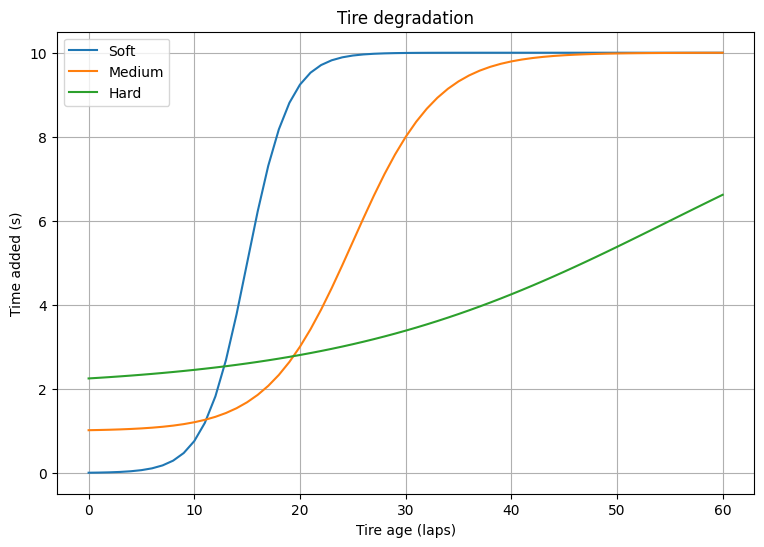

In [20]:
plot_tires(sim)

## Best strategy

Tries every pit lap pair with every set of tires (takes about 20 seconds).

In [21]:
best = find_best_strategy(sim)
best

{'pit_laps': (16, 39),
 'stint_lengths': (15, 23, 22),
 'tire_types': ('Soft', 'Medium', 'Medium'),
 'total_time': 134.27301671848213}

In [22]:
check_close("B1", "find_best_strategy(sim)['total_time']",
            134.2730167184821, best["total_time"])
# 134.27... also found by a separate brute-force search over all 24 ordered tire sequences

check_close("B2", "simulate() on the returned strategy equals the reported total",
            best["total_time"], sim.simulate(best["stint_lengths"], best["tire_types"]))

check("B3", "stint lengths add up to 60 and at least 2 tire types are used", True,
      sum(best["stint_lengths"]) == 60 and len(set(best["tire_types"])) >= 2)

check("B4", "best total is lower than the Part 1 strategy (159.00)", True,
      best["total_time"] < 159.0023725772329)

B1
  Input:    find_best_strategy(sim)['total_time']
  Expected: 134.2730167184821
  Actual:   134.27301671848213
PASS
B2
  Input:    simulate() on the returned strategy equals the reported total
  Expected: 134.27301671848213
  Actual:   134.27301671848213
PASS
B3
  Input:    stint lengths add up to 60 and at least 2 tire types are used
  Expected: True
  Actual:   True
PASS
B4
  Input:    best total is lower than the Part 1 strategy (159.00)
  Expected: True
  Actual:   True
PASS


**Best race, lap by lap** (pit stop laps shown)

In [23]:
best_race = sim.build_race(best["stint_lengths"], best["tire_types"])
best_race[best_race["pit_time"] > 0]

,lap,stint,tire,age,tire_time,pit_time,total_time
15,16,2,Medium,0,1.017341,25.0,26.017341
38,39,3,Medium,0,1.017341,25.0,26.017341
